# Visualise Coarse-Grained results of the Bedload Transport example

### Import relevant packages

In [1]:
from pysammos.data_write.h5.writer import H5XarrayManager

Hello from pysammos
Loading data_write package...


In [2]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.interpolate import griddata
import pyvista as pv
from matplotlib.lines import Line2D

### Initialise data reader manager

In [12]:
help( H5XarrayManager)

Help on class H5XarrayManager in module pysammos.data_write.h5.writer:

class H5XarrayManager(builtins.object)
 |  H5XarrayManager(filename: str)
 |
 |  Manager for reading and writing HDF5 files with array data and converting to xarray Datasets.
 |
 |  Inputs
 |  ------
 |  filename : str
 |      Path to the HDF5 file to read/write.
 |
 |  Examples
 |  --------
 |  >>> manager = H5XarrayManager("data.h5")
 |  >>> manager.add_positions(positions_array)
 |  >>> manager.add_phases(phase_labels)
 |  >>> manager.update_h5py_file(data_dict, dim_index=0, dim_value=0.0)
 |  >>> ds = manager.h5_to_xarray()
 |  >>> print(ds)
 |  HDF5 file structure:
 |      - positions: (n_points, 3) array of grid point positions
 |      - phases: (n_phases,) array of phase labels
 |      - data variables: (time, point, [phase], ...) arrays of data
 |      - time: (n_times,) array of time values
 |
 |  Methods defined here:
 |
 |  __init__(self, filename: str)
 |      Initialize the H5XarrayManager.
 |
 |  add_

In [13]:
manager = H5XarrayManager("./PysammosCG/CG_Lucy_Monodisperse.h5")
bedload_CG = manager.h5_to_xarray()

Processing key: density_mixture
Processing key: fabric_tensor
Processing key: frictional_coefficient_01_Pxy
Processing key: frictional_coefficient_01_Pxyz
Processing key: frictional_coefficient_01_Py
Processing key: frictional_coefficient_Dxy_Pxy
Processing key: frictional_coefficient_Dxy_Pxyz
Processing key: frictional_coefficient_Dxy_Py
Processing key: frictional_coefficient_Dxyz_Pxy
Processing key: frictional_coefficient_Dxyz_Pxyz
Processing key: frictional_coefficient_Dxyz_Py
Processing key: granular_temperature_x
Processing key: granular_temperature_xyz
Processing key: granular_temperature_y
Processing key: granular_temperature_z
Processing key: inertial_number_Sxy_Pxy_d32
Processing key: inertial_number_Sxy_Pxy_d43
Processing key: inertial_number_Sxy_Pxyz_d32
Processing key: inertial_number_Sxy_Pxyz_d43
Processing key: inertial_number_Sxy_Py_d32
Processing key: inertial_number_Sxy_Py_d43
Processing key: positions
Processing key: pressure_x
Processing key: pressure_xy
Processing k

### Data format inspection

In [14]:
bedload_CG.positions

<xarray.DataArray 'positions' (point: 903, xyz: 3)> Size: 22kB
array([[0.00105, 0.001  , 0.     ],
       [0.00105, 0.01295, 0.     ],
       [0.00105, 0.0249 , 0.     ],
       ...,
       [0.5    , 0.2161 , 0.     ],
       [0.5    , 0.22805, 0.     ],
       [0.5    , 0.24   , 0.     ]])
Coordinates:
  * point      (point) int64 7kB 0 1 2 3 4 5 6 7 ... 896 897 898 899 900 901 902
    positions  (point, xyz) float64 22kB 0.00105 0.001 0.0 ... 0.5 0.24 0.0
Dimensions without coordinates: xyz

In [15]:
bedload_CG.time

<xarray.DataArray 'time' (time: 2)> Size: 16B
array([150, 151])
Coordinates:
  * time     (time) int64 16B 150 151

In [16]:
bedload_CG.data_vars

Data variables:
    density_mixture                   (time, point) float32 7kB 671.2 ... 0.0
    fabric_tensor                     (time, point, dim1_3D, dim2_3D) float32 65kB ...
    frictional_coefficient_01_Pxy     (time, point) float32 7kB -0.03122 ... nan
    frictional_coefficient_01_Pxyz    (time, point) float32 7kB -0.04683 ... nan
    frictional_coefficient_01_Py      (time, point) float32 7kB -0.02719 ... nan
    frictional_coefficient_Dxy_Pxy    (time, point) float32 7kB 0.1516 ... nan
    frictional_coefficient_Dxy_Pxyz   (time, point) float32 7kB 0.2274 ... nan
    frictional_coefficient_Dxy_Py     (time, point) float32 7kB 0.132 ... nan
    frictional_coefficient_Dxyz_Pxy   (time, point) float32 7kB 0.5969 ... nan
    frictional_coefficient_Dxyz_Pxyz  (time, point) float32 7kB 0.8954 ... nan
    frictional_coefficient_Dxyz_Py    (time, point) float32 7kB 0.5198 ... nan
    granular_temperature_x            (time, point) float32 7kB 0.0 0.0 ... 0.0
    granular_temperatur

### Plotting the mixture density

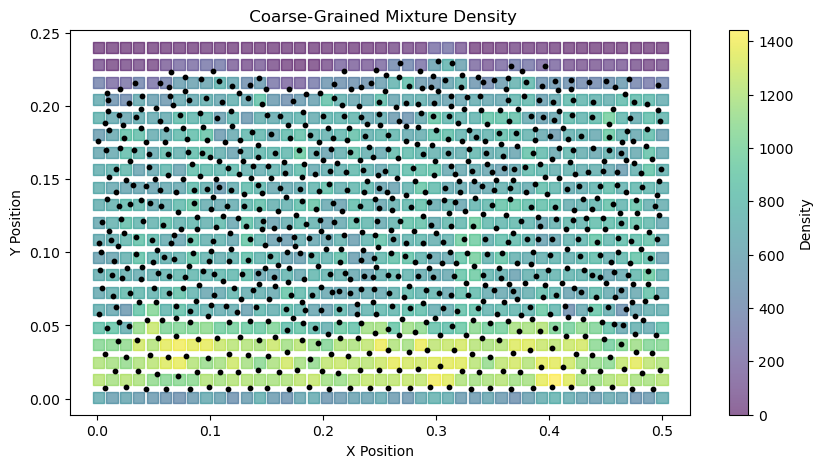

In [17]:
# Create figure and axis
fig = plt.figure(figsize=(10,5))
ax = fig.add_subplot(111)

# Plot DEM particle positions 
bedload_DEM = pv.read('../data_examples/bedload_transport/DEM_data/DES_FB1_0150.vtp')
bedload_particles = bedload_DEM.points
x_particle = bedload_particles[:, 0]; y_particle = bedload_particles[:, 1]
ax.scatter(x_particle, y_particle, s=10, c='k', alpha=1, label='Particle Positions', zorder=3)

# Plot the CG data
x = np.asarray(bedload_CG.positions[:, 0]) 
y = np.asarray(bedload_CG.positions[:, 1])
z = np.asarray(bedload_CG.positions[:, 2])
var = np.asarray(bedload_CG.density_mixture.values[0, :])
sc = ax.scatter(x, y, s=65, c=var, 
                cmap='viridis', alpha=0.6, label='CG Density', 
                zorder=1, marker='s')

# Add colorbar and labels
plt.colorbar(sc, ax=ax, label='Density')
ax.set_xlabel('X Position')
ax.set_ylabel('Y Position')
ax.set_title(' Coarse-Grained Mixture Density')
plt.show()

### Granular temperature in slices

In [24]:
# initialise data reader manager
manager_gt = H5XarrayManager("./PysammosCG/CG_GranularTemperature_slices.h5")
slices_gt = manager_gt.h5_to_xarray()

Processing key: granular_temperature_Kamrin
Processing key: granular_temperature_LAMMPS
Processing key: positions
Processing key: time


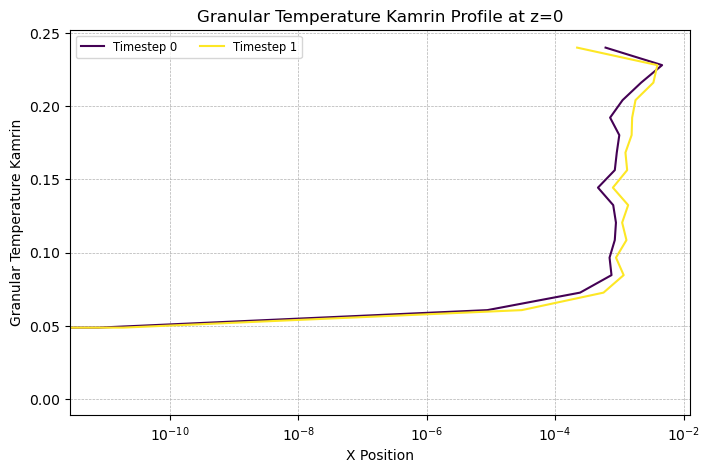

In [25]:
fig, ax = plt.subplots(figsize=(8,5))
num_timesteps = slices_gt.granular_temperature_Kamrin.shape[0]
colors = plt.cm.viridis(np.linspace(0, 1, num_timesteps))

for i in range(num_timesteps):
    ax.plot(slices_gt.granular_temperature_Kamrin[i,:,0], slices_gt.positions[:, 1], color=colors[i], label=f'Timestep {i}')

ax.set_xlabel('X Position')
ax.set_ylabel('Granular Temperature Kamrin')
ax.set_title('Granular Temperature Kamrin Profile at z=0')
ax.legend(loc='best', fontsize='small', ncol=2)
#gridlines
ax.grid(visible=True, which='both', linestyle='--', linewidth=0.5)
# log scale x axis
ax.set_xscale('log')
plt.show()

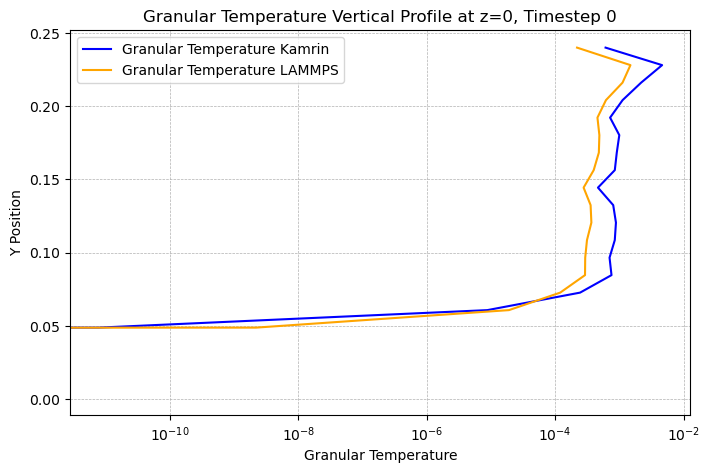

In [26]:
# plot first time step vertical profile comparing Kamrin and LAMMPS
fig, ax = plt.subplots(figsize=(8,5))
ax.plot(slices_gt.granular_temperature_Kamrin[0,:,0], slices_gt.positions[:, 1], label='Granular Temperature Kamrin', color='blue')
ax.plot(slices_gt.granular_temperature_LAMMPS[0,:,0], slices_gt.positions[:, 1], label='Granular Temperature LAMMPS', color='orange')
ax.set_xlabel('Granular Temperature')
ax.set_ylabel('Y Position')
ax.set_title('Granular Temperature Vertical Profile at z=0, Timestep 0')
#gridlines
ax.grid(visible=True, which='both', linestyle='--', linewidth=0.5)
# log scale x axis
ax.set_xscale('log')
ax.legend()
plt.show()  